# Combined vs separate — analysis across all three experiments

Pick an experiment with `EXPERIMENT` below. All three that have been run so far are wired up:

| key | what it is | runs |
|---|---|---|
| `sweep-400ep` | folder 12's training-method sweep: 16 hyperparameter cells x 2 archs x 2 seeds x 4 thresholds, 400 epochs | 254 |
| `long-1000ep-a` | first long run: adam lr=0.003 b=256 init=normal, 7 thresholds, 1 seed, 1000 epochs | 14 |
| `long-1000ep-b` | second long run: adam lr=0.006 b=128 init=normal, 5 thresholds, 1 seed, 1000 epochs | 10 |

Where an experiment has **multiple seeds** the curves are seed-averaged (individual seeds shown
as faint dots). Where it has **multiple hyperparameter cells**, `CELL` selects one for the detail
figures, and a dedicated section compares *all* cells at once.

Reference predictors are computed per split and cached per (split, threshold-set):
`ideal-alpha` (knows the true table -- the floor), **`context-Bayes`** (the exact posterior
predictive under this generator's prior -- the true ceiling for any context-only predictor),
`ctx-count` (add-eps counts), and the in-arch hand construction.

Every series carries its own colour **and** marker **and** linestyle (Okabe-Ito CVD-safe family),
so identity never rests on colour alone.


In [7]:
import csv, glob, importlib.util, json, os
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# ── EDIT HERE ────────────────────────────────────────────────────────────────
EXPERIMENT = 'long-1000ep-a'      # 'sweep-400ep' | 'long-1000ep-a' | 'long-1000ep-b'
CELL       = None                 # None -> the experiment's default cell; or an explicit cell tag
# ─────────────────────────────────────────────────────────────────────────────

_F12 = os.path.join('..', '12. training level exhaustive experiment to confirm finding')
EXPERIMENTS = {
    'sweep-400ep':   dict(runs=os.path.join(_F12, 'runs'), cell=None,
                          note='16 cells x 2 archs x 2 seeds x 4 thresholds, 400 ep'),
    'long-1000ep-a': dict(runs='runs', cell='opt-adam_lr-0.003_b-256_init-normal_ep-1000',
                          note='adam lr=0.003 b=256, 7 thresholds, 1 seed, 1000 ep'),
    'long-1000ep-b': dict(runs='runs', cell='opt-adam_lr-0.006_b-128_init-normal_ep-1000',
                          note='adam lr=0.006 b=128, 5 thresholds, 1 seed, 1000 ep'),
}
EXP = EXPERIMENTS[EXPERIMENT]
RUNS_DIR = EXP['runs']

DIVERGE_CUTOFF = 5.0    # nats; healthy curves live in ~[0,2.4]. Guards the rare Adam spike
                        # (folder 12 had 7 such runs, all separate, thr=1.0, adam lr=0.01).

# RUNS[(cell, arch, thr)] = [metrics, ...] one per seed
RUNS = defaultdict(list)
for mp in sorted(glob.glob(os.path.join(RUNS_DIR, '*', 'metrics_*.json'))):
    m = json.load(open(mp))
    h = m['history']
    m.setdefault('final_train', h['train_loss'][-1])   # folder 12 predates these fields
    m.setdefault('final_test',  h['test_loss'][-1])
    RUNS[(m['cell'], m['arch'], m['threshold'])].append(m)
for v in RUNS.values():
    v.sort(key=lambda m: m['seed'])

ALL_CELLS = sorted({c for c, _, _ in RUNS})
if CELL is None:
    CELL = EXP['cell'] or ALL_CELLS[0]
assert CELL in ALL_CELLS, f'{CELL!r} not in {ALL_CELLS}'

ARCHS = ['combined', 'separate']
THRS  = sorted({t for c, _, t in RUNS if c == CELL})
SEEDS = sorted({m['seed'] for v in RUNS.values() for m in v})
CFG   = RUNS[(CELL, 'combined', THRS[0])][0]['config']

ARTIFACTS_DIR = os.path.join('artifacts', EXPERIMENT, CELL)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print(f"EXPERIMENT = {EXPERIMENT!r}   ({EXP['note']})")
print(f'runs dir   : {RUNS_DIR}')
print(f'cells      : {len(ALL_CELLS)}   seeds: {SEEDS}   thresholds: {THRS}')
print(f'selected   : CELL = {CELL!r}')
print(f"config     : {CFG['optimizer']} lr={CFG['lr']} b={CFG['batch_size']} init={CFG['init']} "
      f"epochs={CFG['epochs']}")
print(f'artifacts  : {ARTIFACTS_DIR}/')
if len(ALL_CELLS) > 1:
    print(f'\n({len(ALL_CELLS)} cells available -- the all-cells section below compares them;')
    print(' set CELL to any of these for the detail figures:)')
    for c in ALL_CELLS: print(f'   {c}')

def runs_of(arch, thr, cell=None):
    """All seeds for one (arch, threshold), diverged trajectories dropped."""
    return [m for m in RUNS[(cell or CELL, arch, thr)]
            if max(m['history']['train_loss']) <= DIVERGE_CUTOFF]

def agg(arch, thr, key, cell=None):
    """(mean over seeds, [per-seed values]) for a scalar metric."""
    vals = [m[key] for m in runs_of(arch, thr, cell)]
    return (float(np.mean(vals)) if vals else float('nan')), vals

print(f"\n{'thr':>5s} {'arch':>9s} {'n':>2s} {'best_train':>11s} {'test@best':>10s} "
      f"{'final_te':>9s} {'epochs':>7s}")
for t in THRS:
    for a in ARCHS:
        rs = runs_of(a, t)
        if not rs: continue
        bt, _ = agg(a, t, 'best_train'); tb, _ = agg(a, t, 'test_at_best')
        ft, _ = agg(a, t, 'final_test')
        print(f"{t:5.1f} {a:>9s} {len(rs):2d} {bt:11.4f} {tb:10.4f} {ft:9.4f} "
              f"{int(np.mean([m['epochs_run'] for m in rs])):7d}")
n_drop = sum(len(v) for v in RUNS.values()) - sum(
    len(runs_of(a, t)) for t in THRS for a in ARCHS)


EXPERIMENT = 'long-1000ep-a'   (adam lr=0.003 b=256, 7 thresholds, 1 seed, 1000 ep)
runs dir   : runs
cells      : 2   seeds: [0]   thresholds: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
selected   : CELL = 'opt-adam_lr-0.003_b-256_init-normal_ep-1000'
config     : adam lr=0.003 b=256 init=normal epochs=1000
artifacts  : artifacts/long-1000ep-a/opt-adam_lr-0.003_b-256_init-normal_ep-1000/

(2 cells available -- the all-cells section below compares them;
 set CELL to any of these for the detail figures:)
   opt-adam_lr-0.003_b-256_init-normal_ep-1000
   opt-adam_lr-0.006_b-128_init-normal_ep-1000

  thr      arch  n  best_train  test@best  final_te  epochs
  0.4  combined  1      1.7738     1.8124    1.8124    1000
  0.4  separate  1      1.7584     1.7836    1.7837    1000
  0.5  combined  1      1.7037     1.7395    1.7402    1000
  0.5  separate  1      1.6953     1.7202    1.7203    1000
  0.6  combined  1      1.6039     1.6302    1.6302    1000
  0.6  separate  1      1.5943     1.6143  

## Reference predictors (no training)

Ported from folder 11's `simplified_setting.ipynb`. Computed on **both** splits and cached to
`artifacts/baseline_ce_cache.json`, keyed by (split, threshold-set, eps) so different experiments
with different threshold lists coexist without evicting each other.

The construction forward pass runs on **CPU** and in chunks — this box's GPUs are often saturated,
and the full split would otherwise materialise a huge attention tensor at once.


In [8]:
SPLITS = ['train', 'test']
DATA_DIR    = os.path.join(_F12, 'dataset')
TOKEN_START = CFG['token_start']
TOKEN_END   = CFG['seq_len']
CONSTRUCTION_EPS = 0.01     # folder-11 convention. NOTE: not the optimal smoothing -- see below.
BASELINE_BATCH   = 256

_spec = importlib.util.spec_from_file_location('t14', 'train.py')
_t14 = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_t14)
SimplifiedTransformerMLP = _t14.SimplifiedTransformerMLP

def load_blob(split, thr):
    return torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)

def ideal_alpha_dist(blob, alpha):
    """Knows the true 2-successor table AND its probabilities -> the CE floor."""
    x_np = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_arr = np.array([[trans[b][v] for v in range(Vs)] for b in range(B)], dtype=np.int64)
    prob_arr  = np.array([[probs[b][v] for v in range(Vs)] for b in range(B)], dtype=np.float64)
    p_win = np.zeros((B, W, V_)); last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < Vs
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        ar = np.arange(B)
        s0, s1 = trans_arr[ar, last_sig, 0], trans_arr[ar, last_sig, 1]
        q0, q1 = prob_arr[ar, last_sig, 0],  prob_arr[ar, last_sig, 1]
        p = np.zeros((B, V_)); p[:, Vs:] = (1.0 - alpha) / n_noise
        p[ar, s0] += alpha * q0; p[ar, s1] += alpha * q1
        p_win[:, t - TOKEN_START] = p
    return p_win

def ctx_count_dist(blob, alpha, eps=0.01):
    """Empirical successor counts of the current state, smoothed by eps, scaled by alpha, plus
    the exact noise floor == what a perfect induction head outputs."""
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V_, Vs)); pending = np.zeros((B, V_))
    last_ruled = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), q] + eps
        p = np.zeros((B, V_))
        p[:, :Vs] = cnt / cnt.sum(axis=1, keepdims=True) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win

import itertools, functools

_PAIRS = list(itertools.combinations(range(CFG['v_sig']), 2))   # the 6 unordered successor pairs
_QG  = np.linspace(0.1, 0.9, 401)                               # q ~ U(0.1,0.9) from data_generation
_LQ, _L1Q = np.log(_QG), np.log(1 - _QG)

@functools.lru_cache(maxsize=None)
def _bayes_pred(n_tup):
    """Exact posterior predictive over the signal states given this state's successor counts.
    (1) eliminate every successor-pair that misses an observed successor -> those tokens get
    EXACTLY zero; (2) weigh each surviving pair by q^{n_a}(1-q)^{n_b}, the likelihood of the
    counts; (3) average the pairs' predictions. Rows are drawn independently per state in
    data_generation.py, so the current state's counts are a sufficient statistic."""
    Vs_ = len(n_tup)
    n = np.array(n_tup, float)
    valid = [(a, b) for a, b in _PAIRS
             if not any(n[j] > 0 for j in range(Vs_) if j not in (a, b))]
    if not valid:
        return np.ones(Vs_) / Vs_
    logs = [n[a] * _LQ + n[b] * _L1Q for a, b in valid]
    C = max(l.max() for l in logs)          # stabilise: q**50 underflows in float64
    num = np.zeros(Vs_); den = 0.0
    for (a, b), l in zip(valid, logs):
        w = np.exp(l - C)
        den    += w.sum()
        num[a] += (w * _QG).sum()
        num[b] += (w * (1 - _QG)).sum()
    return num / den

def true_bayes_dist(blob, alpha):
    """Bayes-OPTIMAL context-only predictor for THIS generator (2-of-4 successors, split
    q~U(0.1,0.9)). Identical count bookkeeping to ctx_count_dist -- only the readout differs,
    so any gap between the two curves is purely the estimator, not the statistics."""
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts = np.zeros((B, V_, Vs)); pending = np.zeros((B, V_))
    last_ruled = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        rows = trans_counts[np.arange(B), q]
        p = np.zeros((B, V_))
        p[:, :Vs] = np.array([_bayes_pred(tuple(r)) for r in rows]) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        _step(t)
    return p_win


def _build_construction_attn(V, T, Vs, dev):
    """Hand-set combined Wqk/Wov implementing folder 10's PerfectInductionTransformer circuit,
    converted to combined form via W_qk = Wq^T@Wk, W_ov = Wv^T@Wo^T (exact reparametrization)."""
    D = V + T
    Wq1 = torch.eye(D, device=dev) * (D ** 0.5)
    T1 = torch.zeros(D, D, device=dev)
    for k in range(Vs, V): T1[k, :] = -1e9
    for tq in range(T):
        for tk in range(T):
            T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
    Wk1 = T1.t()
    Wv1 = torch.zeros(D, D, device=dev); Wv1[:V, :V] = torch.eye(V, device=dev)
    Wo1 = torch.eye(D, device=dev)
    in2 = D + D
    Wq2 = torch.zeros(D, in2, device=dev)
    Wq2[:Vs, :Vs]    = torch.eye(Vs, device=dev) * (D ** 0.5) * 1000.0
    Wq2[:Vs, D:D+Vs] = torch.eye(Vs, device=dev) * (D ** 0.5) * 50.0
    for v in range(V): Wq2[Vs, v] = (D ** 0.5) * 10.0
    Wk2 = torch.zeros(D, in2, device=dev); Wk2[:V, D:D+V] = torch.eye(V, device=dev)
    for v in range(Vs, V): Wk2[Vs, v] = -50000.0
    Wv2 = torch.zeros(D, in2, device=dev); Wv2[:V, :V] = torch.eye(V, device=dev)
    Wo2 = torch.eye(D, device=dev)
    return Wq1.t() @ Wk1, Wv1.t() @ Wo1.t(), Wq2.t() @ Wk2, Wv2.t() @ Wo2.t()

_CONSTRUCTION_CACHE = {}

def build_construction_model(V, T, Vs, dev):
    m = SimplifiedTransformerMLP(V, T, V + T, Vs, CFG['freeze_hidden_k'], bias=True,
                                 attn_param='combined').to(dev)
    Wqk1, Wov1, Wqk2, Wov2 = _build_construction_attn(V, T, Vs, dev)
    with torch.no_grad():
        m.layer1.W_qk.copy_(Wqk1); m.layer1.W_ov.copy_(Wov1)
        m.layer2.W_qk.copy_(Wqk2); m.layer2.W_ov.copy_(Wov2)
        m.ff2.weight.zero_(); m.ff2.bias.zero_()                        # dormant FFN
        m.fc_out.weight.zero_()
        m.fc_out.weight[:V, m.in2:m.in2 + V] = torch.eye(V, device=dev)   # identity selector
        m.fc_out.bias.zero_()
    for p in m.parameters(): p.requires_grad_(False)
    m.eval(); return m

@torch.no_grad()
def construction_dist(blob, alpha, eps=CONSTRUCTION_EPS, dev=torch.device('cpu')):
    V = blob['total_vocab']; Vs = blob['vocab_set1']; T = blob['seq_len']
    key = (V, T, Vs, str(dev))
    if key not in _CONSTRUCTION_CACHE:
        _CONSTRUCTION_CACHE[key] = build_construction_model(V, T, Vs, dev)
    logits = _CONSTRUCTION_CACHE[key](blob['x'].to(dev))[:, TOKEN_START:TOKEN_END]
    f = logits[..., :Vs].clamp_min(0.0)
    psig = alpha * (f + eps) / (f + eps).sum(-1, keepdim=True)
    pn = torch.full(psig.shape[:-1] + (V - Vs,), (1.0 - alpha) / (V - Vs), device=psig.device)
    return torch.cat([psig, pn], dim=-1).cpu().numpy()

def _ce_from_win(p_win, y_np):
    yw = y_np[:, TOKEN_START:TOKEN_END]; B, W = yw.shape
    bb = np.arange(B)[:, None]; ww = np.arange(W)[None, :]
    return float((-np.log(np.maximum(p_win[bb, ww, yw], 1e-12))).mean())

def _construction_ce_chunked(blob, alpha, batch=BASELINE_BATCH):
    """Chunked so a large split never materialises a full [B,T,T] tensor at once."""
    x_all, y_all = blob['x'], blob['y']
    tot_nll = tot_n = 0
    for i in range(0, x_all.shape[0], batch):
        sub = dict(blob); sub['x'] = x_all[i:i + batch]; sub['y'] = y_all[i:i + batch]
        p = construction_dist(sub, alpha)
        yw = sub['y'].numpy()[:, TOKEN_START:TOKEN_END]; b, w = yw.shape
        bb = np.arange(b)[:, None]; ww = np.arange(w)[None, :]
        tot_nll += -np.log(np.maximum(p[bb, ww, yw], 1e-12)).sum(); tot_n += b * w
    return tot_nll / tot_n

# ── compute (or load) the baselines, per split ───────────────────────────────
CACHE_PATH = os.path.join('artifacts', 'baseline_ce_cache.json')
os.makedirs('artifacts', exist_ok=True)
cache_all = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
if 'thresholds' in cache_all:                       # migrate the oldest flat format
    cache_all = {cache_all.get('split', 'test'): cache_all}

def _ckey(split):
    """Keyed by threshold-set too, so experiments with different alpha lists coexist."""
    return f"{split}|{','.join(str(t) for t in THRS)}|{CONSTRUCTION_EPS}"

BASE_CE = {}
for split in SPLITS:
    k = _ckey(split)
    entry = cache_all.get(k)
    if entry is None and cache_all.get(split, {}).get('thresholds') == THRS \
            and cache_all.get(split, {}).get('eps') == CONSTRUCTION_EPS:
        entry = cache_all[split]                    # reuse a legacy split-only entry
        cache_all[k] = entry
    if entry is not None and 'bayes' not in entry:
        print(f'back-filling true-Bayes for the {split} split (other baselines reused)...')
        entry['bayes'] = [_ce_from_win(true_bayes_dist(load_blob(split, t), t),
                                       load_blob(split, t)['y'].numpy()) for t in THRS]
        cache_all[k] = entry
        json.dump(cache_all, open(CACHE_PATH, 'w'), indent=2)
    if entry is None:
        print(f'computing baselines on the {split} split (CPU, chunked)...')
        ideal, ctx, constr, bayes = [], [], [], []
        for t in THRS:
            blob = load_blob(split, t); y_np = blob['y'].numpy()
            ideal.append(_ce_from_win(ideal_alpha_dist(blob, t), y_np))
            bayes.append(_ce_from_win(true_bayes_dist(blob, t), y_np))
            ctx.append(_ce_from_win(ctx_count_dist(blob, t), y_np))
            constr.append(_construction_ce_chunked(blob, t))
            print(f'  thr={t}: ideal={ideal[-1]:.4f} bayes={bayes[-1]:.4f} '
                  f'ctx={ctx[-1]:.4f} constr={constr[-1]:.4f}', flush=True)
        entry = {'thresholds': THRS, 'eps': CONSTRUCTION_EPS, 'split': split,
                 'ideal': ideal, 'bayes': bayes, 'ctx': ctx, 'construction': constr}
        cache_all[k] = entry
        json.dump(cache_all, open(CACHE_PATH, 'w'), indent=2)
        print(f'cached -> {CACHE_PATH} [{k}]')
    else:
        print(f'loaded cached baselines <- {CACHE_PATH} [{k}]')
    BASE_CE[split] = entry

IDEAL_CE  = BASE_CE['test']['ideal']
BAYES_CE  = BASE_CE['test']['bayes']
CTX_CE    = BASE_CE['test']['ctx']
CONSTR_CE = BASE_CE['test']['construction']


computing baselines on the train split (CPU, chunked)...
  thr=0.4: ideal=1.7339 bayes=1.7627 ctx=1.7978 constr=1.7943
  thr=0.5: ideal=1.6721 bayes=1.6991 ctx=1.7301 constr=1.7293
  thr=0.6: ideal=1.5718 bayes=1.5977 ctx=1.6259 constr=1.6281
  thr=0.7: ideal=1.4266 bayes=1.4520 ctx=1.4776 constr=1.4825
  thr=0.8: ideal=1.2355 bayes=1.2599 ctx=1.2834 constr=1.2915
  thr=0.9: ideal=0.9782 bayes=1.0024 ctx=1.0242 constr=1.0346
  thr=1.0: ideal=0.5713 bayes=0.5949 ctx=0.6157 constr=0.6285
cached -> artifacts/baseline_ce_cache.json [train|0.4,0.5,0.6,0.7,0.8,0.9,1.0|0.01]
computing baselines on the test split (CPU, chunked)...
  thr=0.4: ideal=1.7338 bayes=1.7627 ctx=1.7984 constr=1.7944
  thr=0.5: ideal=1.6732 bayes=1.7005 ctx=1.7320 constr=1.7313
  thr=0.6: ideal=1.5703 bayes=1.5961 ctx=1.6232 constr=1.6259
  thr=0.7: ideal=1.4274 bayes=1.4520 ctx=1.4779 constr=1.4831
  thr=0.8: ideal=1.2348 bayes=1.2596 ctx=1.2837 constr=1.2914
  thr=0.9: ideal=0.9781 bayes=1.0020 ctx=1.0239 constr=1.03

## 1. CE vs alpha — train and test side by side

Both panels come from the **same** best-train checkpoint (`best_train` on the left,
`test_at_best` on the right), so they show one model state from two angles rather than two
different models. Shared y-axis, so the panels are directly comparable by eye. With multiple
seeds the line is the seed mean and the faint dots are individual seeds.

**context-Bayes is the real bound.** `ctx-count` is just add-eps smoothing — Bayes-optimal only
under a Dirichlet prior, which this generator is not. The true posterior (a) puts *exactly zero*
on the two structurally impossible successors once both real ones are seen, and (b) never lets a
successor exceed q=0.9, so it keeps mass on an as-yet-unobserved second successor. No eps can do
either. A trained model landing between ctx-count and context-Bayes is therefore expected, not
anomalous; landing *below* context-Bayes would be impossible.


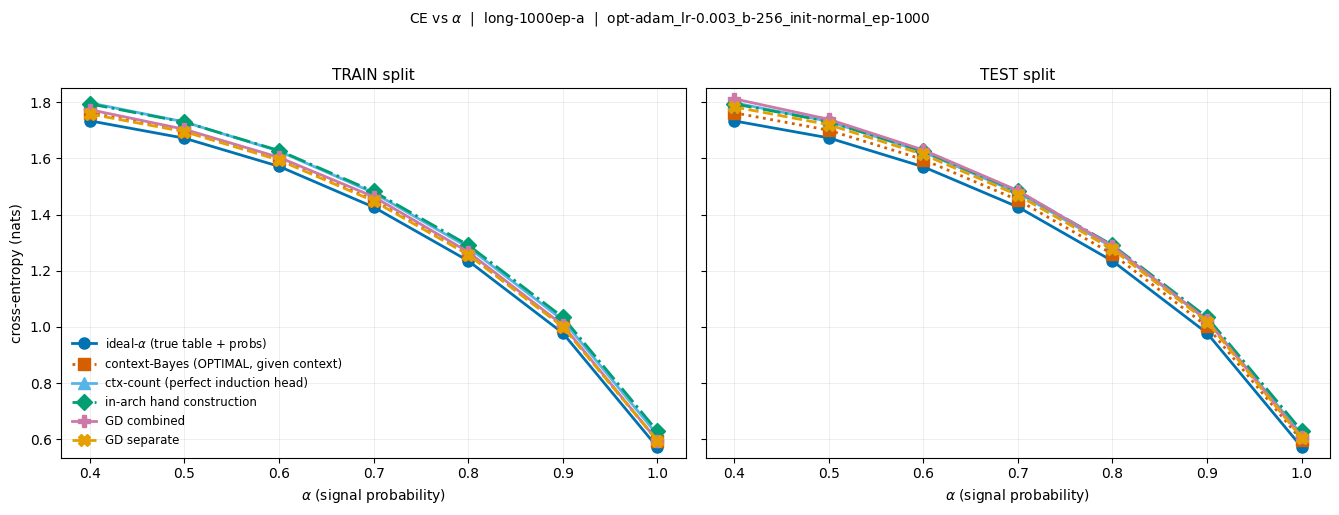


=== TRAIN split (models at their best-train checkpoint) ===
  thr    ideal    BAYES      ctx   constr  combined  separate  comb-sep  sep-Bayes
  0.4   1.7339   1.7627   1.7978   1.7943    1.7738    1.7584   +0.0154    -0.0043
  0.5   1.6721   1.6991   1.7301   1.7293    1.7037    1.6953   +0.0085    -0.0038
  0.6   1.5718   1.5977   1.6259   1.6281    1.6039    1.5943   +0.0096    -0.0034
  0.7   1.4266   1.4520   1.4776   1.4825    1.4638    1.4483   +0.0155    -0.0037
  0.8   1.2355   1.2599   1.2834   1.2915    1.2673    1.2571   +0.0102    -0.0028
  0.9   0.9782   1.0024   1.0242   1.0346    1.0064    1.0003   +0.0060    -0.0021
  1.0   0.5713   0.5949   0.6157   0.6285    0.5947    0.5950   -0.0003    +0.0001
fraction of the ctx-count -> Bayes gap closed:
    thr=0.4: combined   68.5%   separate  112.4%
    thr=0.5: combined   85.1%   separate  112.4%
    thr=0.6: combined   78.0%   separate  112.1%
    thr=0.7: combined   53.9%   separate  114.4%
    thr=0.8: combined   68.9%   

In [9]:
# Okabe-Ito CVD-safe family; each series also has its own marker + linestyle so identity never
# depends on colour alone (validated: normal-vision dE 18.4, worst CVD dE 7.6 + secondary encoding)
SERIES = {
    'ideal':        dict(color='#0072B2', marker='o', ls='-',  label=r'ideal-$\alpha$ (true table + probs)'),
    'bayes':        dict(color='#D55E00', marker='s', ls=':',  label='context-Bayes (OPTIMAL, given context)'),
    'ctx':          dict(color='#56B4E9', marker='^', ls='-',  label='ctx-count (perfect induction head)'),
    'construction': dict(color='#009E73', marker='D', ls='-.', label='in-arch hand construction'),
    'combined':     dict(color='#CC79A7', marker='P', ls='-',  label='GD combined'),
    'separate':     dict(color='#E69F00', marker='X', ls='--', label='GD separate'),
}
MODEL_KEY = {'train': 'best_train', 'test': 'test_at_best'}

def model_series(arch, split, cell=None):
    """(means, per-seed scatter points) across thresholds."""
    means, pts = [], []
    for t in THRS:
        mu, vals = agg(arch, t, MODEL_KEY[split], cell)
        means.append(mu); pts += [(t, v) for v in vals]
    return means, pts

_all = [v for sp in SPLITS for v in
        (BASE_CE[sp]['ideal'] + BASE_CE[sp]['bayes'] + BASE_CE[sp]['ctx'] +
         BASE_CE[sp]['construction'] +
         model_series('combined', sp)[0] + model_series('separate', sp)[0])]
_all = [v for v in _all if np.isfinite(v)]
pad = 0.03 * (max(_all) - min(_all))
ylim = (min(_all) - pad, max(_all) + pad)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)
for ax, split in zip(axes, SPLITS):
    for key in ['ideal', 'bayes', 'ctx', 'construction']:
        st = SERIES[key]; ys = BASE_CE[split][{'ideal': 'ideal', 'bayes': 'bayes',
                                               'ctx': 'ctx', 'construction': 'construction'}[key]]
        ax.plot(THRS, ys, color=st['color'], marker=st['marker'], ls=st['ls'],
                lw=2, ms=8, label=st['label'])
    for arch in ARCHS:
        st = SERIES[arch]; means, pts = model_series(arch, split)
        lbl = st['label'] + (f' (mean of {len(SEEDS)} seeds)' if len(SEEDS) > 1 else '')
        ax.plot(THRS, means, color=st['color'], marker=st['marker'], ls=st['ls'],
                lw=2, ms=8, label=lbl)
        if len(SEEDS) > 1 and pts:
            ax.scatter(*zip(*pts), s=14, color=st['color'], alpha=0.4, zorder=3)
    ax.set_xlabel(r'$\alpha$ (signal probability)')
    ax.set_ylim(*ylim); ax.grid(alpha=0.25, lw=0.6)
    ax.set_title(f'{split.upper()} split', fontsize=11)
axes[0].set_ylabel('cross-entropy (nats)')
axes[0].legend(fontsize=8.5, frameon=False)
fig.suptitle(f'CE vs $\\alpha$  |  {EXPERIMENT}  |  {CELL}', y=1.02, fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'ce_vs_alpha_train_test.png'), dpi=140,
            bbox_inches='tight')
plt.show()

for split in SPLITS:
    B = BASE_CE[split]
    print(f'\n=== {split.upper()} split (models at their best-train checkpoint) ===')
    print(f"{'thr':>5s} {'ideal':>8s} {'BAYES':>8s} {'ctx':>8s} {'constr':>8s} "
          f"{'combined':>9s} {'separate':>9s} {'comb-sep':>9s} {'sep-Bayes':>10s}")
    for i, t in enumerate(THRS):
        c_, _ = agg('combined', t, MODEL_KEY[split])
        s_, _ = agg('separate', t, MODEL_KEY[split])
        print(f"{t:5.1f} {B['ideal'][i]:8.4f} {B['bayes'][i]:8.4f} {B['ctx'][i]:8.4f} "
              f"{B['construction'][i]:8.4f} {c_:9.4f} {s_:9.4f} {c_ - s_:+9.4f} "
              f"{s_ - B['bayes'][i]:+10.4f}")
    # how much of the ctx-count -> Bayes headroom each architecture actually captures
    print(f"fraction of the ctx-count -> Bayes gap closed:")
    for i, t in enumerate(THRS):
        span = B['ctx'][i] - B['bayes'][i]
        if span <= 0: continue
        c_, _ = agg('combined', t, MODEL_KEY[split]); s_, _ = agg('separate', t, MODEL_KEY[split])
        print(f"    thr={t}: combined {100*(B['ctx'][i]-c_)/span:6.1f}%   "
              f"separate {100*(B['ctx'][i]-s_)/span:6.1f}%")


## 2. All hyperparameter cells at once

Only meaningful for `sweep-400ep` (16 cells). Left: a small-multiple per cell, combined vs
separate seed-averaged against the ctx-count reference. Right, as its own figure: the mean
combined−separate gap per cell, ranked — the compact view of the whole sweep.


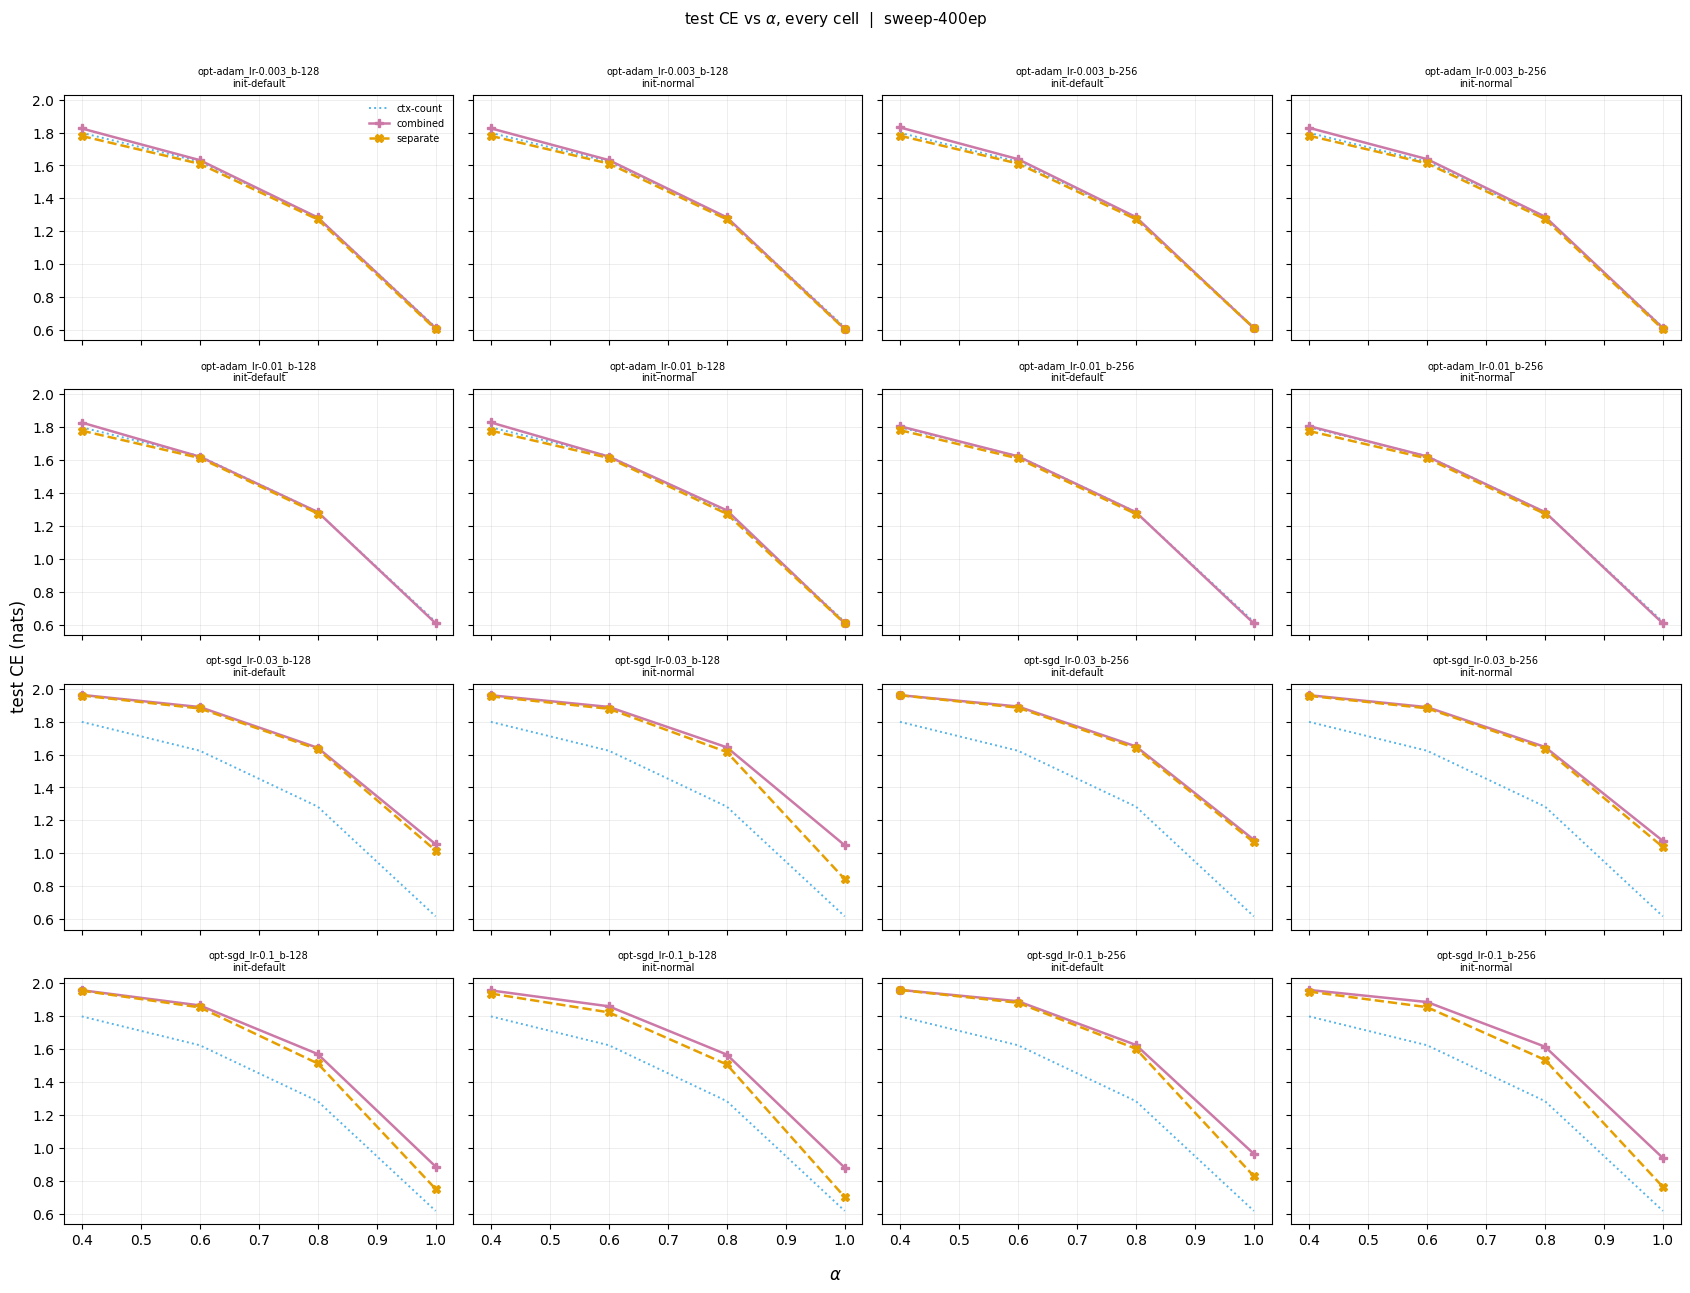

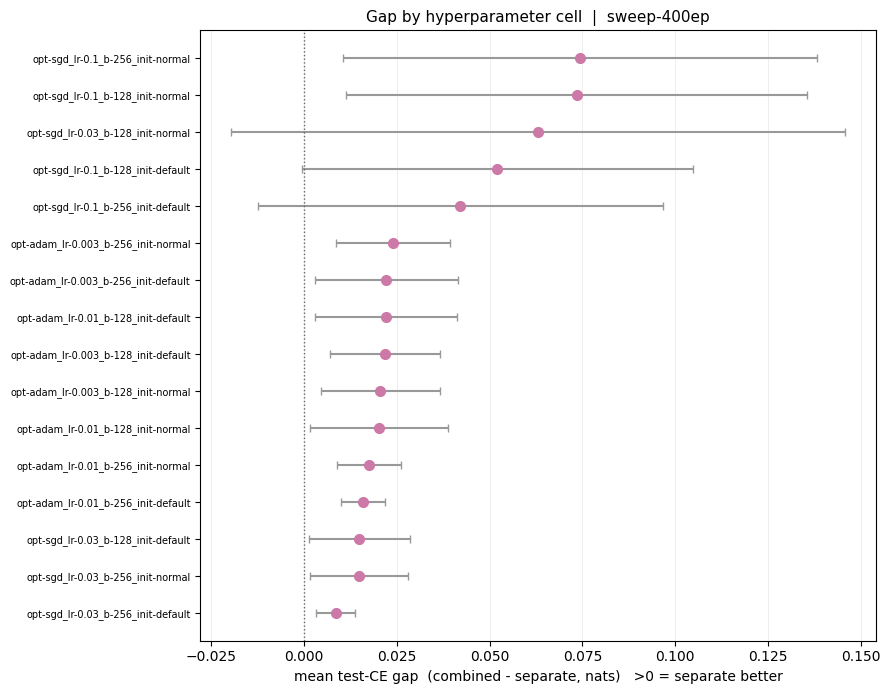

cell                                            mean gap  sd over thr
opt-sgd_lr-0.03_b-256_init-default               +0.0085       0.0053
opt-sgd_lr-0.03_b-256_init-normal                +0.0149       0.0132
opt-sgd_lr-0.03_b-128_init-default               +0.0149       0.0136
opt-adam_lr-0.01_b-256_init-default              +0.0159       0.0059
opt-adam_lr-0.01_b-256_init-normal               +0.0175       0.0086
opt-adam_lr-0.01_b-128_init-normal               +0.0202       0.0186
opt-adam_lr-0.003_b-128_init-normal              +0.0206       0.0160
opt-adam_lr-0.003_b-128_init-default             +0.0218       0.0149
opt-adam_lr-0.01_b-128_init-default              +0.0221       0.0191
opt-adam_lr-0.003_b-256_init-default             +0.0222       0.0193
opt-adam_lr-0.003_b-256_init-normal              +0.0240       0.0153
opt-sgd_lr-0.1_b-256_init-default                +0.0421       0.0546
opt-sgd_lr-0.1_b-128_init-default                +0.0521       0.0527
opt-sgd_lr-0.03_b-12

In [4]:
if len(ALL_CELLS) > 1:
    ncol = 4
    nrow = int(np.ceil(len(ALL_CELLS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.2 * nrow),
                             squeeze=False, sharex=True, sharey=True)
    for i, cl in enumerate(ALL_CELLS):
        ax = axes[i // ncol][i % ncol]
        thrs_c = sorted({t for c, _, t in RUNS if c == cl})
        ax.plot(THRS, CTX_CE, color=SERIES['ctx']['color'], ls=':', lw=1.4, label='ctx-count')
        for arch in ARCHS:
            st = SERIES[arch]
            ys = [agg(arch, t, 'test_at_best', cl)[0] for t in thrs_c]
            ax.plot(thrs_c, ys, color=st['color'], marker=st['marker'], ls=st['ls'],
                    lw=1.8, ms=6, label=arch)
        ax.set_title(cl.replace('_init', '\ninit'), fontsize=7)
        ax.grid(alpha=0.25, lw=0.6)
        if i == 0: ax.legend(fontsize=7, frameon=False)
    for j in range(len(ALL_CELLS), nrow * ncol):
        axes[j // ncol][j % ncol].axis('off')
    fig.supxlabel(r'$\alpha$'); fig.supylabel('test CE (nats)')
    fig.suptitle(f'test CE vs $\\alpha$, every cell  |  {EXPERIMENT}', y=1.005, fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join('artifacts', EXPERIMENT, 'all_cells_grid.png'), dpi=140,
                bbox_inches='tight')
    plt.show()

    # ranked mean gap per cell (averaged over thresholds AND seeds)
    rows = []
    for cl in ALL_CELLS:
        gaps = []
        for t in sorted({tt for c, _, tt in RUNS if c == cl}):
            c_, _ = agg('combined', t, 'test_at_best', cl)
            s_, _ = agg('separate', t, 'test_at_best', cl)
            if np.isfinite(c_) and np.isfinite(s_): gaps.append(c_ - s_)
        if gaps: rows.append((cl, float(np.mean(gaps)), float(np.std(gaps))))
    rows.sort(key=lambda r: r[1])

    fig, ax = plt.subplots(figsize=(9, 0.34 * len(rows) + 1.6))
    ys = np.arange(len(rows))
    ax.errorbar([r[1] for r in rows], ys, xerr=[r[2] for r in rows], fmt='o',
                color='#CC79A7', ecolor='#999999', ms=7, capsize=3)
    ax.axvline(0, color='0.4', lw=1, ls=':')
    ax.set_yticks(ys); ax.set_yticklabels([r[0] for r in rows], fontsize=7)
    ax.set_xlabel('mean test-CE gap  (combined - separate, nats)   >0 = separate better')
    ax.set_title(f'Gap by hyperparameter cell  |  {EXPERIMENT}', fontsize=11)
    ax.grid(alpha=0.25, lw=0.6, axis='x')
    fig.tight_layout()
    fig.savefig(os.path.join('artifacts', EXPERIMENT, 'gap_by_cell.png'), dpi=140,
                bbox_inches='tight')
    plt.show()

    print(f"{'cell':46s} {'mean gap':>9s} {'sd over thr':>12s}")
    for cl, mu, sd in rows:
        print(f'{cl:46s} {mu:+9.4f} {sd:12.4f}')
else:
    print(f'{EXPERIMENT} has a single cell -- nothing to compare here.')


## 3. Training trajectories

One panel per threshold, train and test, epoch 0 = the random init. Log-scaled x so the early
transient and the long tail are both legible. With multiple seeds every seed is drawn.


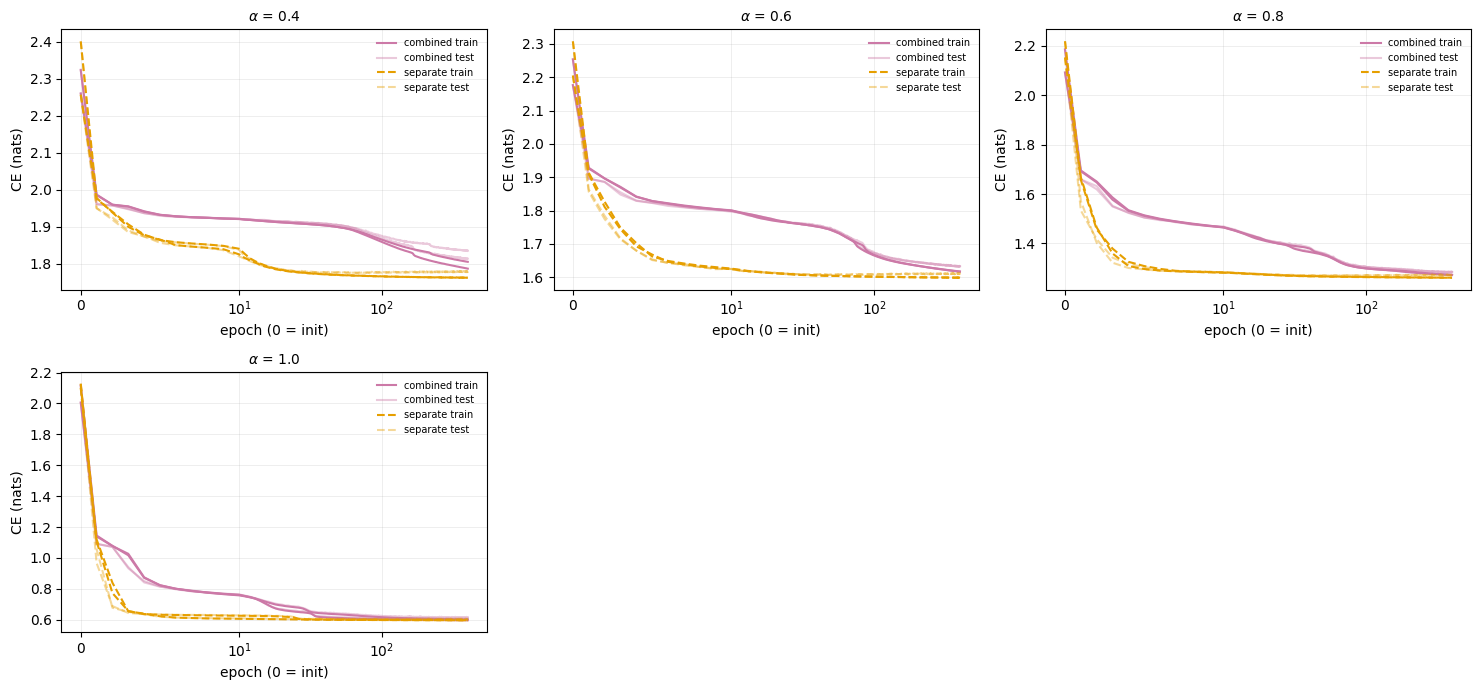

saved 4 per-threshold figures -> artifacts/sweep-400ep/opt-adam_lr-0.003_b-128_init-default/curve_x_<thr>.png


In [5]:
ncols = 3
nrows = int(np.ceil(len(THRS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.5 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            for key, al in [('train_loss', 1.0), ('test_loss', 0.4)]:
                y = np.array(m['history'][key])
                ax.plot(np.arange(len(y)), y, color=st['color'], ls=st['ls'], lw=1.5, alpha=al,
                        label=f"{a} {key.split('_')[0]}" if m['seed'] == SEEDS[0] else None)
    ax.set_xscale('symlog', linthresh=10)
    ax.set_title(rf'$\alpha$ = {t}', fontsize=10)
    ax.set_xlabel('epoch (0 = init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'curves_grid.png'), dpi=140, bbox_inches='tight')
plt.show()

for i, t in enumerate(THRS):
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            for key, al in [('train_loss', 1.0), ('test_loss', 0.4)]:
                y = np.array(m['history'][key])
                ax.plot(y, color=st['color'], ls=st['ls'], lw=1.6, alpha=al,
                        label=f"{a} {key.split('_')[0]}" if m['seed'] == SEEDS[0] else None)
    ax.axhline(CTX_CE[i], color=SERIES['ctx']['color'], ls=':', lw=1.4, label='ctx-count (test)')
    ax.axhline(IDEAL_CE[i], color=SERIES['ideal']['color'], ls=':', lw=1.4,
               label=r'ideal-$\alpha$ (test)')
    ax.set_title(rf'$\alpha$ = {t}   ({CFG["epochs"]} epochs)', fontsize=11)
    ax.set_xlabel('epoch (0 = random init)'); ax.set_ylabel('CE (nats)')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, f'curve_x_{t}.png'), dpi=140)
    plt.close(fig)
print(f'saved {len(THRS)} per-threshold figures -> {ARTIFACTS_DIR}/curve_x_<thr>.png')


## 4. Convergence verdict — has combined actually stopped?

Minibatch noise makes a raw tail unreadable, so three diagnostics are used together: **tail
slope** (mean per-epoch change over the last 100 epochs), **100-epoch block means** (equal blocks
= converged, monotonically falling = still crawling), and the **epoch of the minimum**.

The slope test is threshold-sensitive — at higher learning rates a run can read "CONVERGED"
while its block means are still strictly falling. When the two disagree, trust the block means.


  thr      arch seed    slope/ep  last100drop  argmin     of  verdict
  0.4  combined    0   -8.93e-05      0.00893     400    400  still descending
  0.4  combined    1   -9.71e-05      0.00971     400    400  still descending
  0.4  separate    0   -4.89e-06      0.00049     380    400  CONVERGED
  0.4  separate    1   -5.52e-06      0.00055     393    400  CONVERGED
  0.6  combined    0   -6.54e-05      0.00654     396    400  still descending
  0.6  combined    1   -6.61e-05      0.00661     399    400  still descending
  0.6  separate    0   -7.09e-06      0.00071     397    400  CONVERGED
  0.6  separate    1   -4.60e-06      0.00046     393    400  CONVERGED
  0.8  combined    0   -3.56e-05      0.00356     399    400  still descending
  0.8  combined    1   -4.50e-05      0.00450     400    400  still descending
  0.8  separate    0   -4.64e-06      0.00046     387    400  CONVERGED
  0.8  separate    1   -6.47e-06      0.00065     369    400  CONVERGED
  1.0  combined    0   -

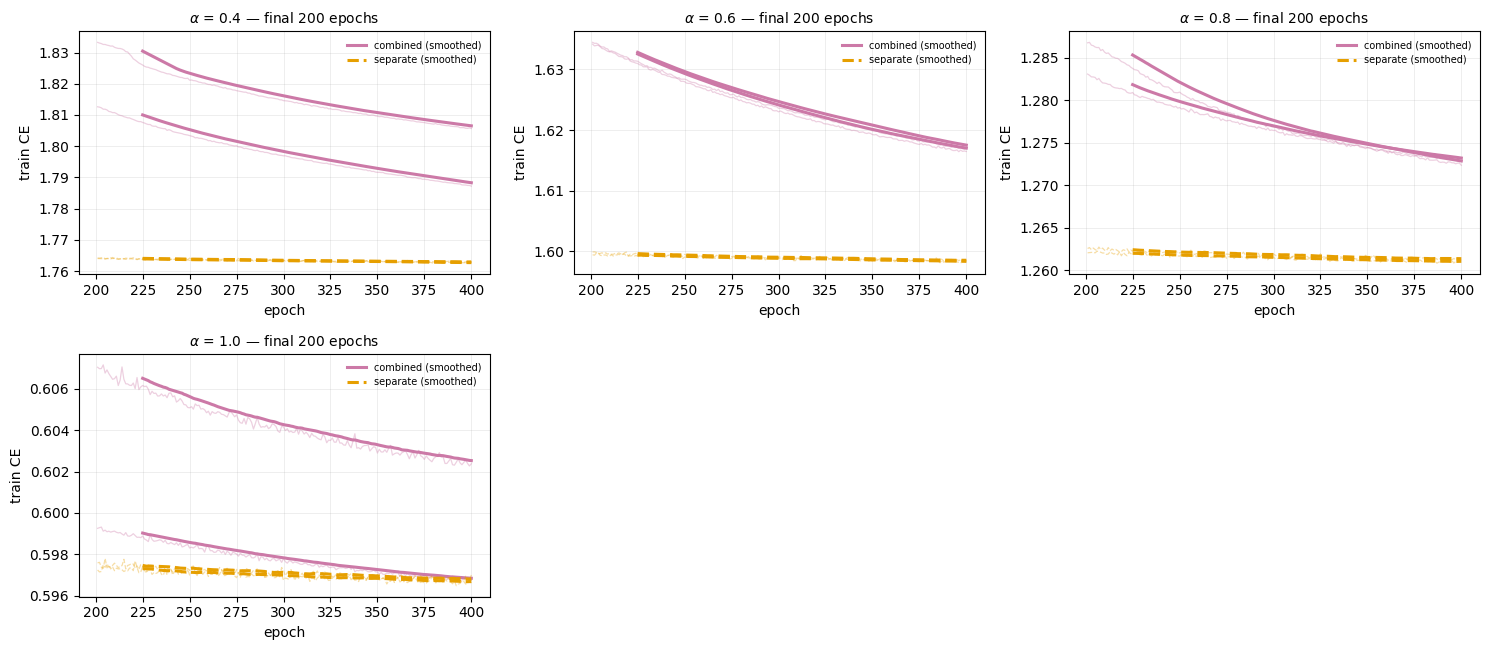

In [6]:
SLOPE_TOL = 1e-5

def tail_slope(y, w=100):
    w = min(w, len(y) - 1)
    return (y[-1] - y[-1 - w]) / w

print(f"{'thr':>5s} {'arch':>9s} {'seed':>4s} {'slope/ep':>11s} {'last100drop':>12s} "
      f"{'argmin':>7s} {'of':>6s}  verdict")
for t in THRS:
    for a in ARCHS:
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            sl = tail_slope(y); drop = y[-101] - y[-1] if len(y) > 101 else np.nan
            print(f"{t:5.1f} {a:>9s} {m['seed']:4d} {sl:+11.2e} {drop:12.5f} "
                  f"{int(y.argmin()):7d} {len(y) - 1:6d}  "
                  f"{'CONVERGED' if sl > -SLOPE_TOL else 'still descending'}")

fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.3 * nrows), squeeze=False)
for i, t in enumerate(THRS):
    ax = axes[i // ncols][i % ncols]
    for a in ARCHS:
        st = SERIES[a]
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            start = max(0, len(y) - 200); k = 25
            ax.plot(np.arange(start, len(y)), y[start:], color=st['color'], ls=st['ls'],
                    lw=0.9, alpha=0.35)
            sm = np.convolve(y[start:], np.ones(k) / k, mode='valid')
            ax.plot(np.arange(start + k - 1, len(y)), sm, color=st['color'], ls=st['ls'],
                    lw=2.2, label=f'{a} (smoothed)' if m['seed'] == SEEDS[0] else None)
    ax.set_title(rf'$\alpha$ = {t} — final 200 epochs', fontsize=10)
    ax.set_xlabel('epoch'); ax.set_ylabel('train CE')
    ax.grid(alpha=0.25, lw=0.6); ax.legend(fontsize=7, frameon=False)
for j in range(len(THRS), nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'convergence_tail.png'), dpi=140, bbox_inches='tight')
plt.show()


In [7]:
BLOCK = 100
nb_blocks = (CFG['epochs'] + BLOCK - 1) // BLOCK
print('Train-CE block means (100-epoch blocks) -- strictly falling blocks == still crawling:')
print(f"{'thr':>5s} {'arch':>9s} {'sd':>3s} " + ' '.join(f'{i * BLOCK:>7d}' for i in range(nb_blocks)))
for t in THRS:
    for a in ARCHS:
        for m in runs_of(a, t):
            y = np.array(m['history']['train_loss'])
            blocks = [y[i:i + BLOCK].mean() for i in range(0, len(y) - 1, BLOCK)]
            mono = all(b2 < b1 for b1, b2 in zip(blocks[3:], blocks[4:]))
            print(f"{t:5.1f} {a:>9s} {m['seed']:3d} " + ' '.join(f'{b:7.4f}' for b in blocks) +
                  ('   [monotone tail]' if mono else ''))


Train-CE block means (100-epoch blocks) -- strictly falling blocks == still crawling:
  thr      arch  sd       0     100     200     300
  0.4  combined   0  1.9030  1.8459  1.8225  1.8099   [monotone tail]
  0.4  combined   1  1.9007  1.8339  1.8039  1.7919   [monotone tail]
  0.4  separate   0  1.7894  1.7649  1.7636  1.7630   [monotone tail]
  0.4  separate   1  1.7892  1.7651  1.7638  1.7631   [monotone tail]
  0.6  combined   0  1.7446  1.6457  1.6282  1.6195   [monotone tail]
  0.6  combined   1  1.7452  1.6466  1.6286  1.6201   [monotone tail]
  0.6  separate   0  1.6221  1.6003  1.5991  1.5985   [monotone tail]
  0.6  separate   1  1.6208  1.6005  1.5993  1.5987   [monotone tail]
  0.8  combined   0  1.3772  1.2904  1.2793  1.2745   [monotone tail]
  0.8  combined   1  1.3782  1.2919  1.2813  1.2745   [monotone tail]
  0.8  separate   0  1.2851  1.2628  1.2618  1.2612   [monotone tail]
  0.8  separate   1  1.2856  1.2633  1.2621  1.2615   [monotone tail]
  1.0  combined   0  0

## 5. Does the gap close over training?

If combined were merely *slow*, the combined−separate gap would head to zero. A gap that
plateaus at a positive value is the signature of a genuinely worse solution. Seed-averaged.


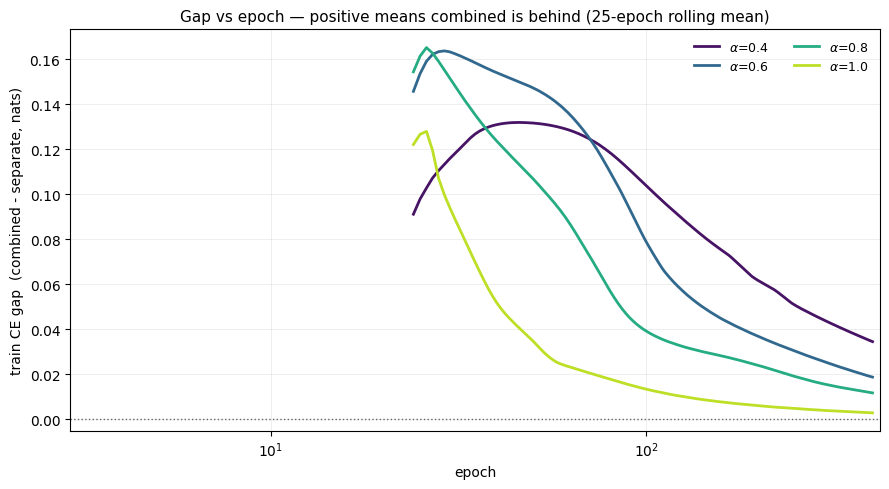

Gap (combined - separate) in train CE by epoch window, + closing extrapolation:
  thr     early       mid     final          trend  ep to close
  0.4    0.1233    0.0640    0.0377      shrinking          429
  0.6    0.1225    0.0381    0.0211      shrinking          352
  0.8    0.0716    0.0248    0.0131      shrinking          376
  1.0    0.0205    0.0064    0.0033      shrinking          266


In [8]:
def mean_curve(arch, thr, key='train_loss'):
    rs = runs_of(arch, thr)
    if not rs: return None
    n = min(len(m['history'][key]) for m in rs)
    return np.mean([m['history'][key][:n] for m in rs], axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
ramp = plt.cm.viridis(np.linspace(0.05, 0.9, len(THRS)))   # sequential: alpha is ordered
for t, col in zip(THRS, ramp):
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    n = min(len(yc), len(ys)); k = 25
    sm = np.convolve(yc[:n] - ys[:n], np.ones(k) / k, mode='valid')
    ax.plot(np.arange(k - 1, n), sm, color=col, lw=2, label=rf'$\alpha$={t}')
ax.axhline(0, color='0.4', lw=1, ls=':')
ax.set_xscale('symlog', linthresh=10)
ax.set_xlabel('epoch'); ax.set_ylabel('train CE gap  (combined - separate, nats)')
ax.set_title('Gap vs epoch — positive means combined is behind (25-epoch rolling mean)',
             fontsize=11)
ax.grid(alpha=0.25, lw=0.6); ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'gap_vs_epoch.png'), dpi=140, bbox_inches='tight')
plt.show()

E = CFG['epochs']
print('Gap (combined - separate) in train CE by epoch window, + closing extrapolation:')
print(f"{'thr':>5s} {'early':>9s} {'mid':>9s} {'final':>9s} {'trend':>14s} {'ep to close':>12s}")
for t in THRS:
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    n = min(len(yc), len(ys)); g = yc[:n] - ys[:n]
    a1, a2, a3 = g[E//10:E//5].mean(), g[2*E//5:E//2].mean(), g[-100:].mean()
    net = tail_slope(yc) - tail_slope(ys)
    eta = a3 / -net if (net < -1e-12 and a3 > 0) else float('inf')
    trend = 'shrinking' if a3 < a2 < a1 else ('flat/widening' if a3 >= a2 else 'mixed')
    eta_s = f'{eta:12.0f}' if np.isfinite(eta) else f'{"n/a":>12s}'
    print(f'{t:5.1f} {a1:9.4f} {a2:9.4f} {a3:9.4f} {trend:>14s} {eta_s}')


## 6. Convergence speed

Epochs each architecture needs to reach a loss level *both* demonstrably reach (the worse of the
two seed-averaged `best_train` values) — this separates "faster" from "better", the two claims
the paper makes independently.


  thr   target  comb ep  sep ep  speedup
  0.4   1.7964      400      15    26.7x


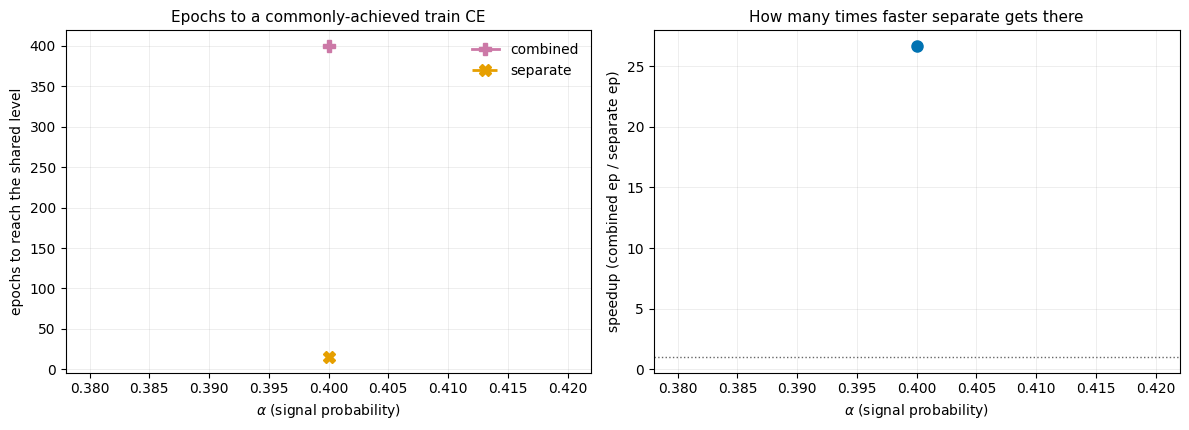

In [9]:
def epochs_to(y, target):
    idx = np.where(np.asarray(y) <= target)[0]
    return int(idx[0]) if len(idx) else None

xs, ratios, ep_c, ep_s = [], [], [], []
print(f"{'thr':>5s} {'target':>8s} {'comb ep':>8s} {'sep ep':>7s} {'speedup':>8s}")
for t in THRS:
    yc, ys = mean_curve('combined', t), mean_curve('separate', t)
    if yc is None or ys is None: continue
    target = max(agg('combined', t, 'best_train')[0], agg('separate', t, 'best_train')[0])
    ec, es = epochs_to(yc, target), epochs_to(ys, target)
    if ec is None or es is None: continue
    xs.append(t); ep_c.append(ec); ep_s.append(es); ratios.append(ec / max(es, 1))
    print(f'{t:5.1f} {target:8.4f} {ec:8d} {es:7d} {ratios[-1]:7.1f}x')

if xs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for a, eps_ in [('combined', ep_c), ('separate', ep_s)]:
        st = SERIES[a]
        axes[0].plot(xs, eps_, color=st['color'], ls=st['ls'], marker=st['marker'],
                     lw=2, ms=8, label=a)
    axes[0].set_ylabel('epochs to reach the shared level')
    axes[0].set_title('Epochs to a commonly-achieved train CE', fontsize=11)
    axes[0].legend(frameon=False)
    axes[1].plot(xs, ratios, color='#0072B2', marker='o', lw=2, ms=8)
    axes[1].axhline(1, color='0.4', lw=1, ls=':')
    axes[1].set_ylabel('speedup (combined ep / separate ep)')
    axes[1].set_title('How many times faster separate gets there', fontsize=11)
    for ax in axes:
        ax.set_xlabel(r'$\alpha$ (signal probability)'); ax.grid(alpha=0.25, lw=0.6)
    fig.tight_layout()
    fig.savefig(os.path.join(ARTIFACTS_DIR, 'speed_vs_alpha.png'), dpi=140, bbox_inches='tight')
    plt.show()


## 7. Master summary

Both splits' baselines and both model measures in one table, written to
`artifacts/<experiment>/<cell>/summary.csv`.


In [10]:
rows = []
for i, t in enumerate(THRS):
    r = {'threshold': t}
    for sp in SPLITS:
        r[f'ideal_{sp}']        = round(BASE_CE[sp]['ideal'][i], 5)
        r[f'bayes_{sp}']        = round(BASE_CE[sp]['bayes'][i], 5)
        r[f'ctx_count_{sp}']    = round(BASE_CE[sp]['ctx'][i], 5)
        r[f'construction_{sp}'] = round(BASE_CE[sp]['construction'][i], 5)
    for a in ARCHS:
        rs = runs_of(a, t)
        if not rs: continue
        r[f'{a}_n_seeds']      = len(rs)
        r[f'{a}_best_train']   = round(agg(a, t, 'best_train')[0], 5)
        r[f'{a}_test_at_best'] = round(agg(a, t, 'test_at_best')[0], 5)
        r[f'{a}_final_test']   = round(agg(a, t, 'final_test')[0], 5)
        r[f'{a}_tail_slope']   = float(f"{np.mean([tail_slope(np.array(m['history']['train_loss'])) for m in rs]):.3e}")
    if runs_of('combined', t) and runs_of('separate', t):
        r['gap_test'] = round(agg('combined', t, 'test_at_best')[0]
                              - agg('separate', t, 'test_at_best')[0], 5)
        r['gap_train'] = round(agg('combined', t, 'best_train')[0]
                               - agg('separate', t, 'best_train')[0], 5)
    rows.append(r)

csv_path = os.path.join(ARTIFACTS_DIR, 'summary.csv')
if rows:
    keys = list(rows[0].keys())
    with open(csv_path, 'w', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=keys); w.writeheader(); w.writerows(rows)
    print(f'wrote {csv_path}\n')
    print(' | '.join(f'{k:>18s}' for k in keys))
    for r in rows:
        print(' | '.join(f'{str(r.get(k, "")):>18s}' for k in keys))

print(f'\nArtifacts in {ARTIFACTS_DIR}/:')
for f in sorted(os.listdir(ARTIFACTS_DIR)):
    print('  ', f)


wrote artifacts/sweep-400ep/opt-adam_lr-0.003_b-128_init-default/summary.csv

         threshold |        ideal_train |        bayes_train |    ctx_count_train | construction_train |         ideal_test |         bayes_test |     ctx_count_test |  construction_test |   combined_n_seeds | combined_best_train | combined_test_at_best | combined_final_test | combined_tail_slope |   separate_n_seeds | separate_best_train | separate_test_at_best | separate_final_test | separate_tail_slope |           gap_test |          gap_train
               0.4 |            1.73394 |            1.76273 |            1.79783 |             1.7943 |            1.73378 |            1.76272 |            1.79841 |            1.79444 |                  2 |            1.79643 |             1.8247 |             1.8247 |          -9.32e-05 |                  2 |            1.76257 |            1.77901 |            1.77928 |         -5.204e-06 |             0.0457 |            0.03386
               0.6 |            